# Young People BMI Exploratory Data Analysis

**Exploratory analysis of 1,010 survey responses to understand which demographic and lifestyle characteristics are associated with body mass index (BMI)**

**Date:** October 20, 2026

## 1. Business context

Organizations that design wellness programs, health campaigns or products for young adults need to know which groups differ in body mass index before deciding where to focus. Survey data can answer that question, but the body measurements reported in a survey have missing answers, implausible values and mixed units, and any of these can distort a comparison between groups. The BMI therefore depends on carefully prepared measurements, which is why the notebook prepares them before comparing any group.

## 2. Project objective

The central question of this project is: **which demographic and lifestyle characteristics are associated with differences in BMI among young survey respondents?** To answer it, the project:
- prepares `Weight` and `Height` by treating their missing and extreme values with documented decisions;
- calculates the BMI of each respondent;
- compares the BMI across the categories of 15 selected categorical variables, including seven 1-to-5 ratings, and measures its correlation with two selected numeric variables; and
- reports the groups whose BMI differs most, together with the data-quality decisions behind the result.

The analysis is descriptive. It identifies associations, not causes.

## 3. Scope and limitations

- The survey was answered in 2013 by 1,010 people, all of Slovak nationality and aged 15 to 30, who were invited by students of a statistics class. It is a convenience sample, so the results should not be generalized to other populations.
- The dataset has 150 columns. This project works with 19 of them: the body measurements and the demographic, health and lifestyle variables that could plausibly relate to BMI. The remaining survey answers (music, movies, phobias, personal opinions and similar) are listed in the data dictionary but not analyzed.
- `Weight` and `Height` come from survey responses and were not independently verified.
- BMI is a screening index based on weight and height. It does not measure body composition or health status.
- Every decision about missing and extreme values is documented, together with the number of records it affects.

## 4. Dataset source

The file used for this project is `responses.csv`, from the [Young People Survey](https://www.kaggle.com/datasets/miroslavsabo/young-people-survey) dataset on Kaggle. The analysis below is based on this file only. The dataset page also offers a `columns.csv` file with the original wording of each survey question, which is not needed to run this notebook; the data dictionary below summarizes the variables used in the analysis.

## 5. Load the data

The CSV file is located in the `data` folder of this project, which makes the analysis easier to reproduce on another computer.

In [1]:
# Import the libraries used to load, inspect, summarize, and visualize the data.
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
# Load the CSV file into a pandas DataFrame and print its number of rows and columns.
df = pd.read_csv('../data/responses.csv')
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 1010
Number of columns: 150


### Data dictionary

The dataset has 150 columns, and not all of them are useful to explain BMI. The 19 columns that could plausibly relate to it are described in detail in the first tables: the two body measurements that define BMI, demographic variables, and health and lifestyle variables. The other 131 columns (music, movies, phobias, personal opinions and similar answers) are only listed at the end and are not analyzed in this project.

#### Body measurements (2 columns)

These two columns define the BMI and are prepared in sections 8 and 9.

| Column | Description | Type |
|---|---|---|
| `Height` | Height of the respondent, in centimeters | Numeric |
| `Weight` | Weight of the respondent, in kilograms | Numeric |

#### Demographic variables (7 columns)

Age, family background and place of upbringing are available for every respondent and are compared against BMI in section 11.

| Column | Description | Type |
|---|---|---|
| `Age` | Age of the respondent, in years | Numeric |
| `Number of siblings` | Number of siblings of the respondent | Numeric |
| `Gender` | Gender of the respondent (`female`, `male`) | Categorical |
| `Education` | Highest education level achieved by the respondent (six levels, from primary school to doctorate) | Categorical |
| `Only child` | Whether the respondent is an only child (yes or no) | Categorical |
| `Village - town` | Whether the respondent spent most of their childhood in a village or a city | Categorical |
| `House - block of flats` | Whether the respondent lived most of their childhood in a house or bungalow, or in a block of flats | Categorical |

#### Health and lifestyle variables (10 columns)

Smoking, drinking, time spent on the internet, eating habits, health concern and interest in sport are the survey answers closest to the habits that could relate to body weight. They are compared against BMI in section 11. The seven 1-to-5 ratings are stored as numbers, but each number stands for an ordered category (a level of agreement or interest), so they are treated as ordinal categorical variables.

| Column | Description | Type |
|---|---|---|
| `Smoking` | Smoking habits, from never having smoked to currently smoking | Categorical |
| `Alcohol` | Drinking habits, from never drinking to drinking a lot | Categorical |
| `Internet usage` | Time spent on the internet, from no time at all to most of the day | Categorical |
| `Healthy eating` | Self-rated healthy lifestyle and eating habits (1 = strongly disagree, 5 = strongly agree) | Categorical (ordinal, 1-5) |
| `Spending on healthy eating` | Willingness to spend more money on healthy food (1 = strongly disagree, 5 = strongly agree) | Categorical (ordinal, 1-5) |
| `Eating to survive` | Agreement with a statement about eating out of necessity without enjoying food (1 = strongly disagree, 5 = strongly agree) | Categorical (ordinal, 1-5) |
| `Health` | Agreement with a statement about worrying about health (1 = strongly disagree, 5 = strongly agree) | Categorical (ordinal, 1-5) |
| `Active sport` | Interest in active sport (1 = not interested, 5 = very interested) | Categorical (ordinal, 1-5) |
| `Passive sport` | Interest in passive sport (1 = not interested, 5 = very interested) | Categorical (ordinal, 1-5) |
| `Adrenaline sports` | Interest in adrenaline sports (1 = not interested, 5 = very interested) | Categorical (ordinal, 1-5) |

#### Derived variable

| Column | Description | Type |
|---|---|---|
| `BMI` | Body mass index, calculated in this notebook as weight in kilograms divided by height in meters squared | Numeric (derived) |

#### Other survey columns (131 columns, not used in this project)

These columns are kept in the file but are not analyzed. They are listed by survey group for completeness.

- **Music preferences (19):** `Music`, `Slow songs or fast songs`, `Dance`, `Folk`, `Country`, `Classical music`, `Musical`, `Pop`, `Rock`, `Metal or Hardrock`, `Punk`, `Hiphop, Rap`, `Reggae, Ska`, `Swing, Jazz`, `Rock n roll`, `Alternative`, `Latino`, `Techno, Trance`, `Opera`
- **Movie preferences (12):** `Movies`, `Horror`, `Thriller`, `Comedy`, `Romantic`, `Sci-fi`, `War`, `Fantasy/Fairy tales`, `Animated`, `Documentary`, `Western`, `Action`
- **Hobbies and interests (29):** `History`, `Psychology`, `Politics`, `Mathematics`, `Physics`, `Internet`, `PC`, `Economy Management`, `Biology`, `Chemistry`, `Reading`, `Geography`, `Foreign languages`, `Medicine`, `Law`, `Cars`, `Art exhibitions`, `Religion`, `Countryside, outdoors`, `Dancing`, `Musical instruments`, `Writing`, `Gardening`, `Celebrities`, `Shopping`, `Science and technology`, `Theatre`, `Fun with friends`, `Pets`
- **Phobias (10):** `Flying`, `Storm`, `Darkness`, `Heights`, `Spiders`, `Snakes`, `Rats`, `Ageing`, `Dangerous dogs`, `Fear of public speaking`
- **Personality traits, views on life and opinions (54):** `Daily events`, `Prioritising workload`, `Writing notes`, `Workaholism`, `Thinking ahead`, `Final judgement`, `Reliability`, `Keeping promises`, `Loss of interest`, `Friends versus money`, `Funniness`, `Fake`, `Criminal damage`, `Decision making`, `Elections`, `Self-criticism`, `Judgment calls`, `Hypochondria`, `Empathy`, `Giving`, `Compassion to animals`, `Borrowed stuff`, `Loneliness`, `Cheating in school`, `Changing the past`, `God`, `Dreams`, `Charity`, `Number of friends`, `Punctuality`, `Lying`, `Waiting`, `New environment`, `Mood swings`, `Appearance and gestures`, `Socializing`, `Achievements`, `Responding to a serious letter`, `Children`, `Assertiveness`, `Getting angry`, `Knowing the right people`, `Public speaking`, `Unpopularity`, `Life struggles`, `Happiness in life`, `Energy levels`, `Small - big dogs`, `Personality`, `Finding lost valuables`, `Getting up`, `Interests or hobbies`, `Parents' advice`, `Questionnaires or polls` (`Punctuality` and `Lying` are text columns)
- **Spending habits (6):** `Finances`, `Shopping centres`, `Branded clothing`, `Entertainment spending`, `Spending on looks`, `Spending on gadgets`
- **Demographics (1):** `Left - right handed`

## 6. Inspect the dataset structure

Before any variable is prepared, the notebook reviews how many columns are numeric and how many are text, and summarizes each group separately. The data types and non-null counts also give a first view of the missing values in the body measurements.

The seven 1-to-5 ratings (`Healthy eating`, `Spending on healthy eating`, `Eating to survive`, `Health`, `Active sport`, `Passive sport` and `Adrenaline sports`) are stored as numbers, but each number stands for an ordered category, such as a level of agreement or interest, so the differences between values are not measured in equal units. For that reason the notebook converts them to ordered categorical columns and treats them as categorical variables from then on.

In [3]:
# Review data types and non-null counts before choosing any transformations.
df = df[['Height', 'Weight', 'Age', 'Number of siblings', 'Gender', 'Education',
         'Only child', 'Village - town', 'House - block of flats', 'Smoking',
         'Alcohol', 'Internet usage', 'Healthy eating', 'Spending on healthy eating',
         'Eating to survive', 'Health', 'Active sport', 'Passive sport', 'Adrenaline sports']]
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1010 entries, 0 to 1009
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Height                      990 non-null    float64
 1   Weight                      990 non-null    float64
 2   Age                         1003 non-null   float64
 3   Number of siblings          1004 non-null   float64
 4   Gender                      1004 non-null   str    
 5   Education                   1009 non-null   str    
 6   Only child                  1008 non-null   str    
 7   Village - town              1006 non-null   str    
 8   House - block of flats      1006 non-null   str    
 9   Smoking                     1002 non-null   str    
 10  Alcohol                     1005 non-null   str    
 11  Internet usage              1010 non-null   str    
 12  Healthy eating              1007 non-null   float64
 13  Spending on healthy eating  1008 non-null   

In [4]:
# Convert the seven 1-to-5 ratings to ordered categorical columns, keeping the order from 1 to 5.
ordinal_columns = [
    "Healthy eating",
    "Spending on healthy eating",
    "Eating to survive",
    "Health",
    "Active sport",
    "Passive sport",
    "Adrenaline sports"
]

for col in ordinal_columns:
    df[col] = pd.Categorical(
        df[col],
        categories=[1, 2, 3, 4, 5],
        ordered=True
    )

In [5]:
# Summarize the numeric variables with descriptive statistics.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Height,990.0,173.514141,10.024505,62.0,167.0,173.0,180.0,203.0
Weight,990.0,66.405051,13.839561,41.0,55.0,64.0,75.0,165.0
Age,1003.0,20.433699,2.828840,15.0,19.0,20.0,22.0,30.0
Number of siblings,1004.0,1.297809,1.013348,0.0,1.0,1.0,2.0,10.0


In [6]:
# Summarize the text variables with counts, unique values and the most frequent value.
cat_vars = df.select_dtypes(include=['object', 'string']).columns
summary = df[cat_vars].describe().T
summary = summary.rename(columns={'count': 'Count', 'unique': 'Unique values',
                                  'top': 'Most frequent value', 'freq': 'Frequency'})
summary

,Count,Unique values,Most frequent value,Frequency
Gender,1004,2,female,593
Education,1009,6,secondary school,621
Only child,1008,2,no,754
Village - town,1006,2,city,707
House - block of flats,1006,2,block of flats,595
Smoking,1002,4,tried smoking,430
Alcohol,1005,3,social drinker,659
Internet usage,1010,4,few hours a day,744


### Initial structure findings

Of the 19 columns analyzed in this project, 17 contain missing values. Both `Height` and `Weight`, the variables used to calculate `BMI`, have missing values that need to be considered during the analysis. Some discrete numerical variables, such as `Age` and the number of siblings, are stored as floats rather than integers. Additionally, `Height` and `Weight` contain some potentially incorrect values that require further investigation. For example, the minimum recorded height is 62 cm, and the minimum weight is 41 kg. Finally, respondents range in age from 15 to 30 years old.

## 7. Assess and handle missing values in the body measurements

BMI needs both `Weight` and `Height`, so a missing value in either one leaves the BMI of that respondent empty. This section reports the number and percentage of missing values in both variables, and how many respondents lack one or both measures. Each variable is missing in about 2% of the respondents, so BMI can be calculated for nearly everyone. Because the share is small, the missing measures are not imputed: replacing them with zero would be wrong, since an unrecorded weight or height is not a recorded value of zero, and replacing them with a typical value would create BMI values that nobody reported. Respondents with a missing measure stay in the dataset, because their other answers are complete, but they have no BMI and are left out of the BMI analysis. The number of respondents affected is reported.

In [7]:
# Count the missing values of Weight and Height and calculate their percentages.
missing_values_height_weight = df[['Height', 'Weight']].isnull().sum()
missing_percentage_height = round(df['Height'].isnull().sum() / len(df) * 100, 2)
missing_percentage_weight = round(df['Weight'].isnull().sum() / len(df) * 100, 2)

missing_summary = pd.DataFrame({
    "Variable": ['Height', 'Weight'],
    "Missing Values": missing_values_height_weight.values,
    "Missing Percentage": [missing_percentage_height, missing_percentage_weight]
    })

missing_summary

,Variable,Missing Values,Missing Percentage
0,Height,20,1.98
1,Weight,20,1.98


In [8]:
# Count how many respondents lack both Height and Weight.
missing_values_both = (df['Height'].isnull() & df['Weight'].isnull()).sum()
print(missing_values_both)

10


### Missing value findings and decision

Approximately 2% of the values in both `Weight` and `Height` are missing. Given the low proportion, handling these missing values (for example, imputing them) may not be necessary.

## 8. Examine the distribution of Weight and Height

`Weight` and `Height` are quantitative continuous variables on a ratio scale: they are measured in kilograms and centimeters, they admit intermediate values, and zero means the absence of the quantity. A histogram is the appropriate chart for this kind of variable because it groups the values into ranges and shows how they are distributed. Plotting both measurements side by side shows whether extreme values are balanced on both sides of the center or concentrated in one tail, which is relevant for the outlier detection in section 9.

Skewness describes the asymmetry of a distribution; a positive value means the tail extends to the right. It is calculated in two ways for each variable: with the pandas method, and with Pearson's second coefficient (three times the difference between the mean and the median, divided by the standard deviation). These are different measures, so their values are not expected to match.

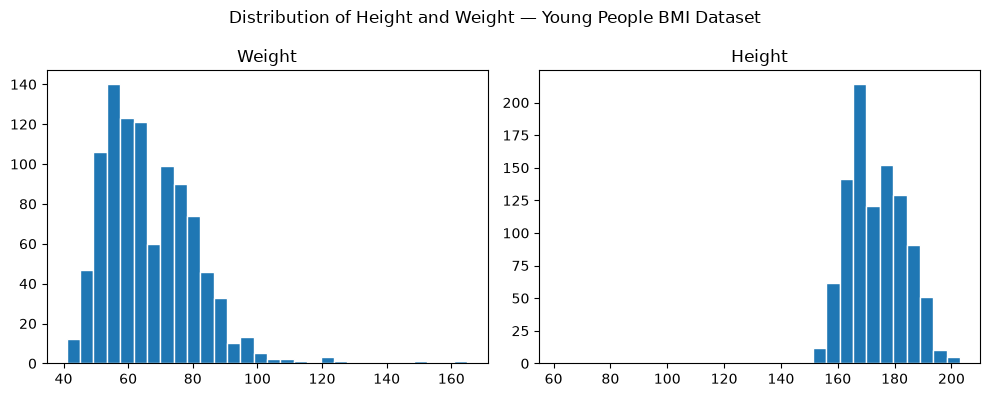

In [9]:
# Draw histograms of Weight and Height side by side to see how the values are distributed.
axes = df[['Weight', 'Height']].hist(
    bins=30,
    figsize=(10, 4),
    layout=(1, 2),
    grid=False,
    edgecolor="white"
)

# Add a title and adjust spacing so it does not overlap the subplot titles.
plt.suptitle("Distribution of Height and Weight — Young People BMI Dataset")
plt.tight_layout()
plt.show()

In [10]:
# Calculate the skewness of Weight and Height with the pandas method.
weight_skewness = df['Height'].skew()
print(weight_skewness)

weight_skewness = df['Weight'].skew()
print(weight_skewness)

-1.1524809388523796
1.2237251927527477


In [11]:
# Calculate Pearson's second coefficient of skewness for Weight and Height from the mean, median and standard deviation.
weight_mean = df['Weight'].mean()
weight_median = df['Weight'].median()
weight_std = df['Weight'].std()
weight_pearson_skewness = 3 * (weight_mean - weight_median) / weight_std
print(f"Pearson's coefficient of skewness for Weight: {weight_pearson_skewness}")

height_mean = df['Height'].mean()
height_median = df['Height'].median()
height_std = df['Height'].std()
height_pearson_skewness = 3 * (height_mean - height_median) / height_std
print(f"Pearson's coefficient of skewness for Height: {height_pearson_skewness}")

Pearson's coefficient of skewness for Weight: 0.5213425215746705
Pearson's coefficient of skewness for Height: 0.15386537773131878


### Weight and Height distribution findings

`Height` has negative skewness according to the pandas method, indicating that most values are concentrated in the higher ranges, with a tail extending to the left. Some extreme values are difficult to distinguish in the histogram, including a recorded height of 62 cm, which may indicate a data entry error and requires further investigation. In contrast, `Weight` has positive skewness, with most values concentrated in the lower ranges and a tail extending to the right. Several extreme values are present, including recorded weights exceeding 160 kg, which should be examined to determine whether they are valid observations or potential data errors.

## 9. Detect outliers in Weight and Height

Extreme values in either measurement would distort the BMI. They are detected with the interquartile range (IQR) rule: a value is an outlier if it is below the first quartile minus 1.5 times the IQR, or above the third quartile plus 1.5 times the IQR. A boxplot shows these values, and the outliers are stored in a separate DataFrame so the decision about them stays documented. The same process is applied to `Weight` and `Height`.

<Axes: xlabel='Weight'>

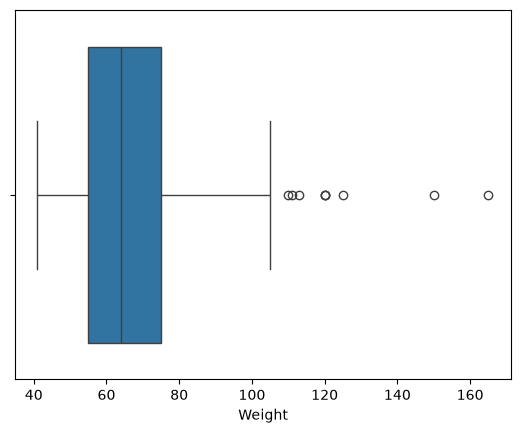

In [12]:
# Draw a boxplot of Weight to see its extreme values.
sns.boxplot(data=df, x='Weight')

In [13]:
# Calculate the IQR limits of Weight, store its outliers in a separate DataFrame and count them.
q1_weight = df['Weight'].quantile(0.25)
q3_weight = df['Weight'].quantile(0.75)
iqr_weight = q3_weight - q1_weight

lower_cap_weight = q1_weight - 1.5 * iqr_weight
upper_cap_weight = q3_weight + 1.5 * iqr_weight

weight_outliers = df[(df['Weight'] < lower_cap_weight) | (df['Weight'] > upper_cap_weight)]
weight_outliers.shape[0]

9

<Axes: xlabel='Height'>

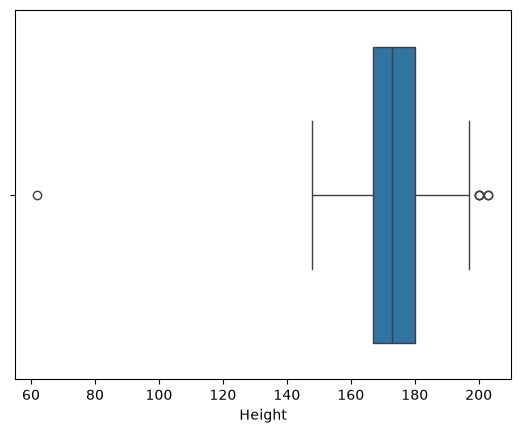

In [14]:
# Draw a boxplot of Height to see its extreme values.
sns.boxplot(data=df, x='Height')

In [15]:
# Calculate the IQR limits of Height, store its outliers in a separate DataFrame and count them.
q1_height = df['Height'].quantile(0.25)
q3_height = df['Height'].quantile(0.75)
iqr_height = q3_height - q1_height

lower_cap_height = q1_height - 1.5 * iqr_height
upper_cap_height = q3_height + 1.5 * iqr_height

height_outliers = df[(df['Height'] < lower_cap_height) | (df['Height'] > upper_cap_height)]
height_outliers.shape[0]

6

In [16]:
# Apply the decision about the outliers of Weight and Height and print how many records it affects.
outlier_indices = weight_outliers.index.union(height_outliers.index)
print("Records removed:", len(outlier_indices))

df.drop(index=outlier_indices, inplace=True)

Records removed: 14


### Weight and Height outlier findings

9 outliers were identified in Weight and 6 in Height. These outliers were identified visually using boxplots, and numerically using the interquartile range rule. These outliers were removed from the DataFrame since they can distort the BMI.

## 10. Calculate BMI and detect its outliers

The body mass index (BMI) is weight in kilograms divided by height in meters squared. Because `Height` is recorded in centimeters, it is converted to meters before the calculation. The same IQR rule is then used to detect respondents with an atypical BMI, which can reveal combinations of weight and height that are implausible even when each value looks acceptable on its own.

In [17]:
# Convert Height to meters and calculate BMI.
df['Height_meters'] = df['Height'] / 100
df['BMI'] = df['Weight'] / (df['Height_meters'] ** 2)

<Axes: xlabel='BMI'>

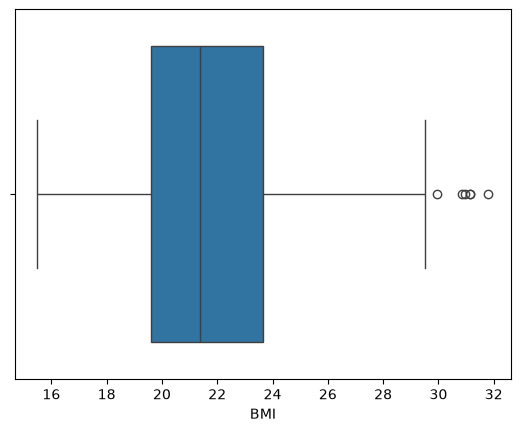

In [18]:
# Draw a boxplot of BMI to see its extreme values.
sns.boxplot(data=df, x='BMI')

In [19]:
# Calculate the IQR limits of BMI, store its outliers in a separate DataFrame and count them.
q1_bmi = df['BMI'].quantile(0.25)
q3_bmi = df['BMI'].quantile(0.75)
iqr_bmi = q3_bmi - q1_bmi

lower_cap_bmi = q1_bmi - 1.5 * iqr_bmi
upper_cap_bmi = q3_bmi + 1.5 * iqr_bmi

bmi_outliers = df[(df['BMI'] < lower_cap_bmi) | (df['BMI'] > upper_cap_bmi)]
bmi_outliers.shape[0]

6

### BMI findings

The BMI variable was derived using Weight and Height. According to the interquartile range rule and the boxplots, there are 6 outliers in the BMI records. They may reflect valid differences between individuals, and removing them without further investigation could lead to information loss or bias the analysis.

## 11. Compare BMI across respondent characteristics

This section answers the central question of the project with the variables selected. For the 15 categorical variables (`Gender`, `Education`, `Smoking`, `Alcohol`, `Internet usage`, `Only child`, `Village - town`, `House - block of flats` and the seven 1-to-5 ratings), boxplots compare the distribution of BMI across their categories. For the two numeric variables (`Age` and `Number of siblings`), the Spearman correlation with BMI shows how strongly, and in which direction, BMI tends to rise or fall with each one, without assuming a straight-line relationship. Both views describe associations, not causes, and the number of respondents in each category is checked before any difference is interpreted, because small groups give unstable results.

In [20]:
# Count the respondents in each category of the selected categorical variables.
cat_vars = [
    'Gender', 'Education', 'Smoking', 'Alcohol', 'Internet usage',
    'Only child', 'Village - town', 'House - block of flats',
    'Healthy eating', 'Spending on healthy eating', 'Eating to survive',
    'Health', 'Active sport', 'Passive sport', 'Adrenaline sports'
]

for column in cat_vars:
    print(df[column].value_counts(dropna=False).sort_index())
    print()

Gender
female    589
male      401
NaN         6
Name: count, dtype: int64

Education
college/bachelor degree             211
currently a primary school pupil     10
doctorate degree                      3
masters degree                       80
primary school                       79
secondary school                    612
NaN                                   1
Name: count, dtype: int64

Smoking
current smoker    184
former smoker     174
never smoked      204
tried smoking     426
NaN                 8
Name: count, dtype: int64

Alcohol
drink a lot       218
never             121
social drinker    652
NaN                 5
Name: count, dtype: int64

Internet usage
few hours a day            735
less than an hour a day    138
most of the day            120
no time at all               3
Name: count, dtype: int64

Only child
no     742
yes    252
NaN      2
Name: count, dtype: int64

Village - town
city       698
village    294
NaN          4
Name: count, dtype: int64

House - block o

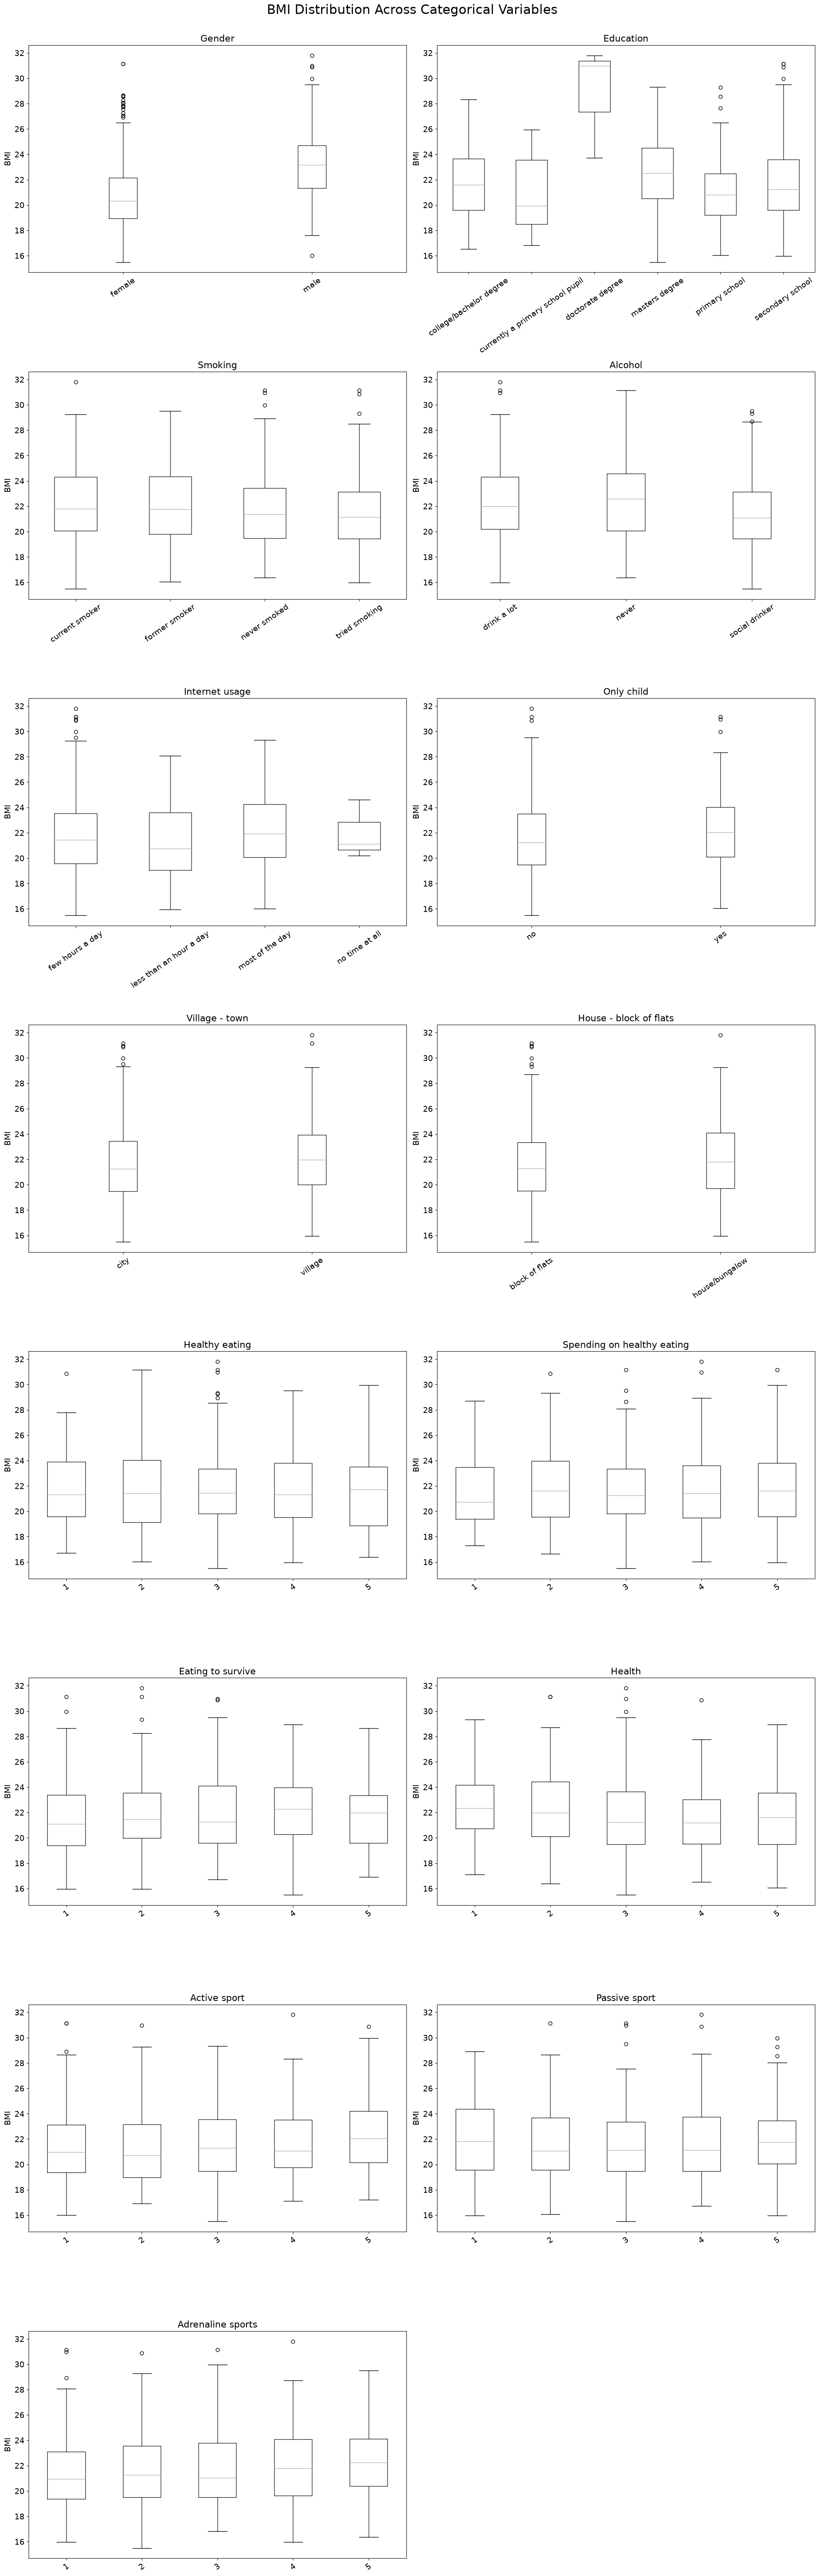

In [21]:
# Draw one boxplot of BMI for each selected categorical variable in a single grid of subplots.
fig, axes = plt.subplots(8, 2, figsize=(20, 62))

for ax, var in zip(axes.flatten(), cat_vars):
    df.boxplot(column="BMI", by=var, ax=ax, grid=False)

    ax.set_title(var, fontsize=16)
    ax.set_xlabel("")
    ax.set_ylabel("BMI", fontsize=14)
    ax.tick_params(axis="x", labelrotation=35, labelsize=14)
    ax.tick_params(axis="y", labelsize=14)

axes.flatten()[-1].set_visible(False)

fig.suptitle("BMI Distribution Across Categorical Variables", fontsize=22, y=1.002)

plt.tight_layout()
plt.show()

In [22]:
# Calculate the Spearman correlation between BMI and each selected numeric variable, sorted from strongest to weakest.
num_vars = df.select_dtypes(include="number")

bmi_corr = num_vars.corr(method="spearman")["BMI"]
bmi_corr = bmi_corr.drop("BMI")
bmi_corr = bmi_corr.reindex(bmi_corr.abs().sort_values(ascending=False).index)

bmi_corr

Weight                0.845658
Height                0.304767
Height_meters         0.304767
Age                   0.201658
Number of siblings   -0.036491
Name: BMI, dtype: float64

### BMI by characteristic findings

**Gender**

Men have a higher median BMI than women in this dataset. However, the distributions overlap, and both groups contain outliers. This indicates a difference in the observed median BMI, but not necessarily a statistically significant difference between the groups.

**Education**

The `doctorate degree` category has a notably higher median BMI than the other education categories. However, this group contains only three observations, so the result should be interpreted with caution. The `currently a primary school pupil` and `primary school` categories have relatively low median BMIs compared with most of the other education groups. Their distributions overlap, although some differences in spread and outliers are visible. The two labels should be checked against the original data documentation to clarify their meanings before considering whether they should be combined.

**Smoking**

The BMI distributions are broadly similar across the four smoking categories. `Current smoker` and `former smoker` appear to have slightly higher median BMIs than `never smoked` and `tried smoking`. Several categories also contain high BMI outliers.

**Alcohol**

People in the `never` category have a slightly higher median BMI than `social drinker`. The `drink a lot` category falls between these two groups. However, the distributions overlap substantially, so the plot does not show a clear separation in BMI across alcohol consumption categories.

**Internet usage**

The `less than an hour a day` category appears to have a lower median BMI than the `few hours a day` and `most of the day` categories. The `no time at all` category has a relatively narrow observed distribution, but it contains only three observations. Therefore, this pattern should be interpreted cautiously, as a small sample may not represent the broader group.

**Only child**

The BMI distributions for people who are only children and those who are not are broadly similar. The `no` category appears to have a slightly wider overall range and includes high outliers, while the `yes` category has a slightly higher median BMI. Nevertheless, the distributions overlap considerably.

**Village - town**

The `village` category appears to have a slightly higher median BMI than the `city` category. However, their distributions are similar in overall spread and overlap substantially, suggesting only a modest visual difference between the groups.

**House - block of flats**

The BMI distributions for `block of flats` and `house/bungalow` are very similar. The `house/bungalow` category appears to have a slightly higher median BMI, but the difference is small, and there is no pronounced visual distinction between the groups.

**Self-reported variables**

The seven ordinal variables `Healthy eating`, `Spending on healthy eating`, `Eating to survive`, `Health`, `Active sport`, `Passive sport`, and `Adrenaline sports` show considerable overlap in BMI distributions across their five response levels.

For `Healthy eating` and `Spending on healthy eating`, the median BMIs remain broadly similar across response levels, with no clear trend. `Eating to survive` and `Health` also show relatively similar distributions, without a consistent pattern across the ratings.

For `Active sport`, the highest response level appears to have a slightly higher median BMI, although the distributions overlap considerably. `Passive sport` shows no clear trend across the five levels. For `Adrenaline sports`, the median BMI appears somewhat higher at the highest interest level, but the differences are modest and do not establish a clear relationship.

These variables measure self-reported attitudes, concerns, and interests rather than necessarily reflecting actual behaviours. Therefore, the observed patterns should be interpreted as descriptive comparisons rather than evidence of causal relationships.

### Overall finding

Most categorical variables show substantial overlap in BMI distributions. `Gender` and `Education` display some of the most noticeable visual differences, although the `doctorate degree` result is based on very few observations. Several categories contain high BMI outliers, which may warrant further investigation but should not automatically be removed. These boxplots provide descriptive insights and do not establish causation.

## 12. Conclusions and next steps

### Key finding

* **Missing values:** Missing values were identified in 17 of the 19 variables analyzed. However, not all variables were equally relevant to the analysis. Missing values should be assessed according to the variables selected for each stage of the analysis rather than handled indiscriminately.

* **Height and Weight:** Both variables contain missing values, representing approximately 2% of the total records for each variable. Given the relatively small proportion of missing data, imputation was not considered necessary for this exploratory analysis. Records with missing Height or Weight were not used to calculate BMI.

* **Height and Weight outliers:** Both variables contain outliers, and Weight shows greater positive skewness than Height. Fourteen records were removed during data cleaning. This decision should be documented alongside the criteria used to identify the outliers, as removing extreme values can affect the resulting BMI distribution.

* **BMI outliers:** BMI also contains outliers. These records were retained because further investigation is needed to determine whether they represent data errors or plausible observations. Outliers should not be removed solely because they fall outside the expected range.

* **Gender:** Men have a higher median BMI than women in this dataset. Although this difference is visible in the boxplots, the distributions overlap, and the result does not establish statistical significance or explain the underlying reasons.

* **Smoking:** BMI distributions are broadly similar across smoking categories, although some differences in median BMI are visible. Former and current smokers appear to have slightly higher median BMIs than some other groups. These observations do not establish a causal relationship between smoking and BMI.

* **Alcohol:** People who report never drinking alcohol have a slightly higher median BMI than social drinkers, while the group reporting that they drink a lot falls between these categories. The distributions overlap considerably, so the observed differences should be interpreted cautiously.

* **Education:** Differences in BMI are visible across education categories, particularly for the doctorate degree group. However, this category contains only three observations, making its distribution unreliable for broader conclusions. The other categories should also be interpreted in light of their respective sample sizes.

* **Internet usage:** Some differences in median BMI are visible across internet-use categories. However, the group reporting no internet use contains only three observations, limiting the reliability of comparisons involving this category.

* **Self-reported variables:** `Healthy eating`, `Spending on healthy eating`, `Eating to survive`, `Health`, `Active sport`, `Passive sport`, and `Adrenaline sports` show considerable overlap in BMI distributions across response levels. No strong or consistent patterns are apparent from the boxplots alone. These variables measure self-reported attitudes, concerns, willingness, and interests rather than necessarily reflecting actual behaviours.

* **Only child, Village - town, and House - block of flats:** BMI distributions are broadly similar across the categories of these variables, with only minor differences in medians or spread. They provide limited visual evidence of an association with BMI in this dataset.

* **Overall conclusion:** Most categorical variables show substantial overlap in BMI distributions. Gender and Education display some of the most noticeable visual differences, although the Education findings require particular caution because of the small doctorate degree group. These findings are descriptive and do not establish causation or statistical significance.


### Data-quality issues

* **Missing values:** Missing values are present in several variables, particularly `Height` and `Weight`, which are needed to calculate `BMI`.
* **Outliers:** Outliers were identified in `Height`, `Weight`, and `BMI`. Their values should be reviewed to determine whether they reflect data-entry errors or plausible observations.


### Next steps

- Investigate the outliers in `Height`, `Weight`, and `BMI` by reviewing their values and checking the available data documentation. Remove observations only when there is sufficient evidence that they are erroneous.
- Compare the results obtained without imputation against those obtained using an appropriate missing-data treatment. Assess whether the conclusions change and document the method used. Imputation should only be applied when justified by the data and analysis requirements.


### Final note

This notebook is an exploratory analysis of survey data, not a health study or a clinical assessment. Its conclusions are limited to the data available in the dataset.